In [1]:
#import os
#os.chdir(r"C:\Users\Visitor\Desktop\publication_word_freq")

In [1]:
from collections import Counter
import re # regular expressions

# Read the text
with open("all_titles_abstracts_for_freq.txt", "r", encoding="utf-8") as f:
    text = f.read()

# Convert to lowercase
text = text.lower()

# Extract words
words = re.findall(r'\b[a-z]+\b', text)



In [2]:
# manually check: 

phrases = ["path integration", 
           "eeg", "electroencephalography", 
           "orientation", "reorientation", "orienting", "oriented", "reoriented", "re-orientation", "reorient", "re-orient", 
           "floor", "ground", 
           "environment", "environmental", "environments", "space",
           "pitch", "pitch rotation", "pitch rotations", "rotations", "rotation", "rotate", "rotated",
           "search", "searched", "searching", 
           "3d", "three-dimensional", "three-dimensionally",
           "locate", "located", "localize", "localized",
           "salient", "salience",
           "imagine", "imagined", "imagining",
           "capacity", "ability"
          ]

for phrase in phrases:
    count = len(re.findall(fr'\b{phrase}\b', text))
    print(f"{phrase}: {count}")



path integration: 4
eeg: 2
electroencephalography: 0
orientation: 0
reorientation: 2
orienting: 1
oriented: 0
reoriented: 0
re-orientation: 0
reorient: 1
re-orient: 0
floor: 9
ground: 4
environment: 2
environmental: 0
environments: 2
space: 1
pitch: 5
pitch rotation: 0
pitch rotations: 3
rotations: 3
rotation: 0
rotate: 0
rotated: 3
search: 4
searched: 3
searching: 1
3d: 3
three-dimensional: 2
three-dimensionally: 2
locate: 4
located: 3
localize: 0
localized: 0
salient: 1
salience: 3
imagine: 1
imagined: 3
imagining: 0
capacity: 3
ability: 3


In [4]:
from wordcloud import STOPWORDS
stopwords = set(STOPWORDS)
#print(stopwords)


In [5]:
more_stop_words = {
    "participants", "participant", "study", "studies",
    "experiments", "experiment",
    "results", "findings", "finding", "research", 
    "used", "use", "using",
    "showed", "show", "found",
    "whether", "without", 
    "group", "self", "less", "larger",
    "investigated", "presented", 
    "suggest", "suggests", "suggested", "suggesting", 
    "indicate", "indicated", "indicates", "indicating", 
    "adults", "either", "task", 
    "e", "occurs", "corners", "effect",
    "different", "leg", 
    "involving", "involves", "single", "start", 
    "early", "room", "objects", "object", 
    "b", "c", "first", "second", "alone", "one", "two", "three", 
    "based", "hypothesis", "testing", "tests", 
    "whereas", "towards", "toward", "together", 
    "training", "trained", "train",
    "tested", "trial", "trials", "multiple", "via", 
    "others", "onto", "along", "reality", "sensory", "salient"
}



In [6]:
common = list(set(stopwords) & set(more_stop_words))
print(common)  

[]


In [7]:
merged_list = list(stopwords | more_stop_words)

filtered_words = [
    word for word in words
    if word not in merged_list
]

word_counts = Counter(filtered_words)

#print(word_counts)

In [8]:
print(len(word_counts))
print(word_counts[len(word_counts)-1, ])

582
0


In [9]:
# Show the 60 most frequent words
for word, count in word_counts.most_common(60):
    print(word, count)


cues 45
landmarks 26
wall 19
spatial 19
height 16
horizontal 16
navigation 14
paths 14
location 13
locations 12
cue 12
visual 12
idiothetic 12
representations 12
path 11
walls 9
floor 9
walked 9
older 9
misophonia 9
information 8
learned 8
combination 8
humans 8
landmark 8
distance 7
angle 7
pigeons 7
variance 7
virtual 7
heading 7
distortions 7
sensory 7
gating 7
integration 6
bayesian 6
locomoted 6
homing 6
topological 6
vertical 5
conflict 5
ceiling 5
pitch 5
immersive 5
north 5
memory 5
localization 5
locomotion 5
adaptation 5
input 5
pointed 5
ratio 5
intersections 5
severity 5
locate 4
search 4
hidden 4
conflicting 4
responses 4
reduced 4


In [8]:
import pandas as pd

word_frequency = pd.DataFrame(
    word_counts.most_common(100),
    columns=["Word", "Frequency"]
)

# deal with repeated words: 
word_frequency["Word"] = word_frequency["Word"].replace({
    "locations": "location",
    "landmarks": "landmark",
    "cues": "cue",
    "paths": "path", 
    "older": "older adults", 
    "virtual": "virtual reality",
    "locomoted": "locomotion",
    "walked": "walk",
    "learned": "learn",
    "learning": "learn",
    "walls": "wall",
    "floor": "ground",
    "space": "environment",
    "pitch": "pitch rotation",
    "rotated": "rotation",
    "rotations": "rotation", 
    "searched": "search",
    "searching": "search",
    "3d": "three-dimensional", 
    "three-dimensionally": "three-dimensional",
    "located": "locate",
    "gating": "sensory gating",
    "human": "humans",
    "pointed": "pointing",
    "headings": "heading",
    "memories": "memory",
    "conflicting": "conflict",
    "horizontally": "horizontal",
    "vertically": "vertical",
    "motion": "self-motion",
    "targets": "target",
    "goal": "target"
    #"capacity": "ability"
})
#print(word_frequency)

word_frequency = (
    word_frequency
    .groupby("Word", as_index=False)["Frequency"]
    .sum()
    .sort_values("Frequency", ascending=False)
)
print(word_frequency.shape)

#word_frequency.iloc[60: ]


(81, 2)


In [9]:
# manually add key words: 
word_frequency.loc[len(word_frequency)] = ["EEG", 2] 
word_frequency.loc[len(word_frequency)] = ["JRD", 2] 

word_frequency.loc[len(word_frequency)] = ["path integration", 4]
word_frequency.loc[len(word_frequency)] = ["orientation", 4]
word_frequency.loc[len(word_frequency)] = ["environment", 5]

word_frequency[word_frequency['Word']=='salience']= ["salience", 4]
word_frequency[word_frequency['Word']=='imagined']= ["imagine", 4]
word_frequency[word_frequency['Word']=='high']= ["high", 4]
word_frequency[word_frequency['Word']=='direction']= ["direction", 8]

print(word_frequency.shape)

word_frequency_sorted = (
    word_frequency
    .groupby("Word", as_index=False)["Frequency"]
    .sum()
    .sort_values("Frequency", ascending=False)
)

(word_frequency_sorted.head(60))



(86, 2)


,Word,Frequency
13,cue,57
41,landmark,34
84,wall,28
55,path,25
46,location,25
32,horizontal,19
73,spatial,19
28,height,16
50,navigation,14
26,ground,13


In [16]:
word_frequency_sorted[word_frequency_sorted['Word']=='motion']

word_frequency_sorted[word_frequency_sorted['Word']=='self-motion']


,Word,Frequency
69,self-motion,4


In [17]:
word_frequency_sorted.iloc[60: ]


,Word,Frequency
30,high,4
35,imagine,4
62,reduced,4
12,coupling,4
29,hidden,4
69,self-motion,4
54,orientation,4
2,ability,3
14,current,3
10,compared,3


In [18]:
# save
word_frequency_sorted.to_csv("publication_word_frequency.csv", index=False)


In [16]:
word_frequency_sorted.dtypes


Word         object
Frequency     int64
dtype: object

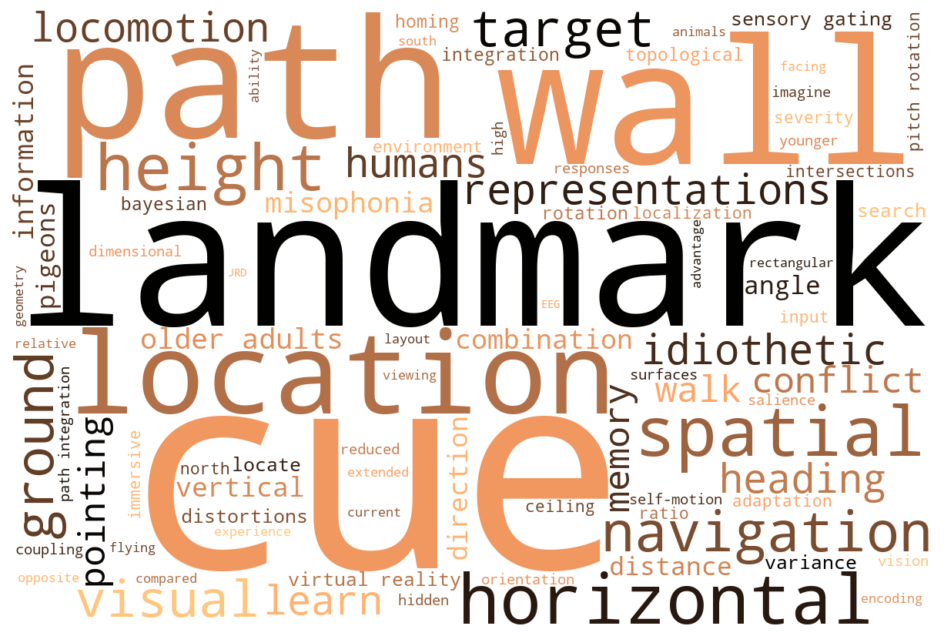

In [19]:
# plot word cloud: 
frequencies = dict(
    zip(word_frequency_sorted["Word"], word_frequency_sorted["Frequency"])
)

from wordcloud import WordCloud
import matplotlib.pyplot as plt

wordcloud = WordCloud(
    width=1200,
    height=800,
    background_color="white",
    colormap='copper'
).generate_from_frequencies(frequencies)

plt.figure(figsize=(12, 8))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()


In [20]:
# save word cloud figure
wordcloud.to_file("publication_word_frequency.png")
print("Word cloud saved!")


Word cloud saved!


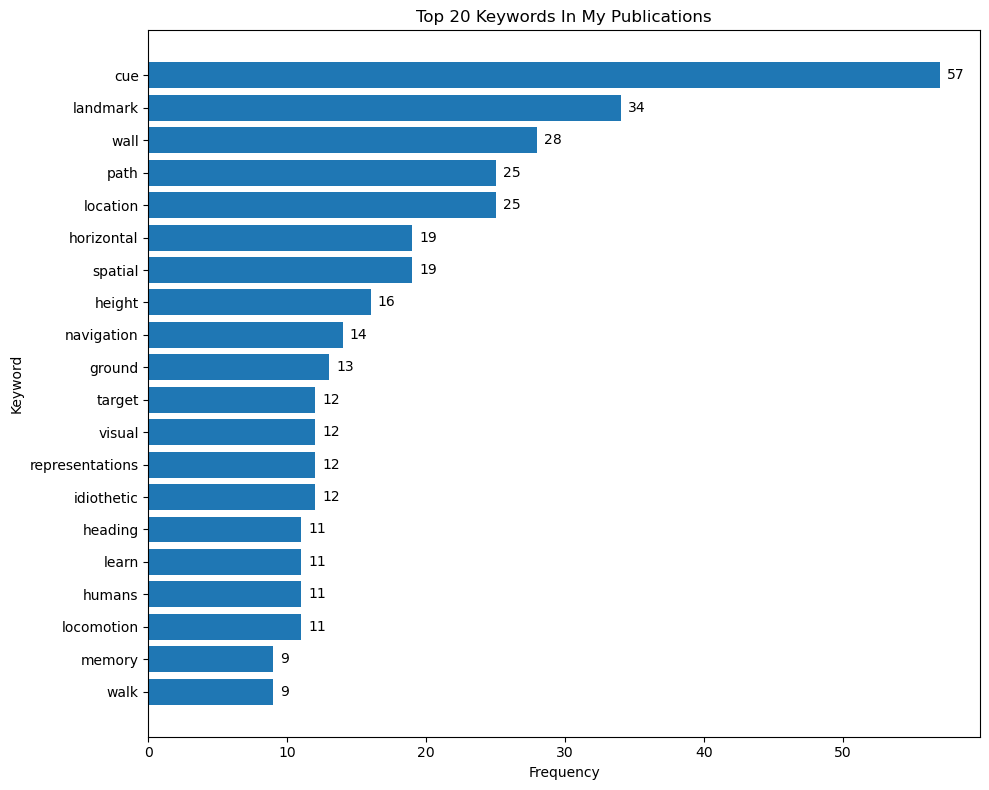

In [21]:
# bar graph for top 20 freq words: 

top20 = word_frequency_sorted.head(20)

fig, ax = plt.subplots(figsize=(10, 8))

bars = ax.barh(top20["Word"], top20["Frequency"])

ax.invert_yaxis()
ax.set_xlabel("Frequency")
ax.set_ylabel("Keyword")
ax.set_title("Top 20 Keywords In My Publications")

# Add frequency labels
for current_bar in bars:
    width = current_bar.get_width()
    ax.text(
        width + 0.5,
        current_bar.get_y() + current_bar.get_height()/2,
        str(int(width)),
        va="center"
    )

fig.tight_layout()
plt.show()


In [22]:
# save top20 figure
fig.savefig(
    "top20_word_frequency.png",
    dpi=300,
    bbox_inches="tight"
)
print("Top 20 bars saved!")


Top 20 bars saved!
